<a href="https://colab.research.google.com/github/SashaVeremchuk/ITMO-data-analysis/blob/main/2_cluster_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Дз№2 Кластерный анализ методом k-средних (k-means)
Анализ данных на Python  
ИТМО 2026   
Веремчук Александра

## Постановка задачи
**Описание данных**   
Набор данных "Леденцы" содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:   
* V1: Я потребляю леденцы, чтобы освежить дыхание  
* V2: Я потребляю леденцы, чтобы чувствовать себя увереннее  
* V3: Я потребляю леденцы, чтобы освежить полость рта   
* V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту  
* V5: Я потребляю леденцы как заменитель других кондитерских изделий  
* V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого  
* V7: Леденцы помогают мне сконцентрироваться  
* V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать  
* V9: Я потребляю леденцы для того, чтобы облегчить боль в горле  
* V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа  
* V11: Я потребляю леденцы для улучшения самочувствия  

**Задача**  
1. Определить число кластеров и обосновать выбор;   
2. Выполнить кластеризацию;  
3. Предложить содержательную интерпретацию полученных групп.



## Подключение библиотек

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster

sns.set(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

In [ ]:
# загрузка данных
df = pd.read_csv("data/lollipops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


In [ ]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [ ]:
for i in df.columns:
  print(f'{i} {df[i].unique()}')


V1 [4 5 3 2]
V2 [5 4 2 3]
V3 [5 4 2 3]
V4 [5 4 2 3]
V5 [3 4 2 5]
V6 [3 4 2 5]
V7 [3 2 4 5]
V8 [3 4 2 5]
V9 [3 4 5 2]
V10 [3 4 5 2]
V11 [3 4 5 2]


**Вывод:**  
Данные нормальные. Пропусков и выбросов нет.   
Нормализовывать данные не нужно, тк данные являются оценочной шкалой, которая уже стандартизирована в значениях от 2 до 5.

## Кластеризация k-means

### Выбор числа кластеров
k-means минимизирует внутрикластерную сумму квадратов и чередует два шага:
* каждая точка относится к ближайшему центру,
* затем центры пересчитываются как средние своих кластеров.

Параметры KMeans:

* `init`="k-means++" (по умолчанию): начальные центры разнесены по данным;
* `n_init`=10: 10 запусков из разных стартов, берётся решение с наименьшей инерцией;
* `random_state`=42: воспроизводимость;

Для начала определим число кластеров при помощи метода Локтя и графика Силуэта и рассчитаем следующие метрики для оценки плотности:  
* `Silhouette` - на сколько объект ближе к своей группе по сравнению с другими группами. [-1; 1], чем ближе к 1 тем лучше.  
* `Calinski-Harabaz` - на сколько плотны кластеры и на сколько далеко разнесены друг от друга. [0; +&infin;], чем больше - тем лучше.   
* `Davis-Bolduin` - оценивает степень перекрытия между кластерами. [0; +&infin;], чем меньше - тем лучше.

* `inertia` - на сколько плотно и кучно точки сгруппированы вокруг своих центров (внутрикластерная сумма квадратов расстояний). Надо смотреть на резкое изменение при смене числа кластеров.

In [ ]:
rows = []
for k in range(2, 12):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(df)
    rows.append({"k": k, "inertia": model.inertia_,
                 "silhouette": silhouette_score(df, model.labels_),
                 "calinski_harabasz": calinski_harabasz_score(df, model.labels_),
                 "davies_bouldin": davies_bouldin_score(df, model.labels_)})
scores = pd.DataFrame(rows)
scores["inertia_down_%"] = (-scores.inertia.pct_change() * 100).round(1)
scores.round(3)

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,inertia_down_%
0,2,1823.304,0.455,246.334,0.930,NaN
1,3,879.717,0.614,434.178,0.784,51.8
2,4,423.144,0.727,720.103,0.433,51.9
3,5,326.246,0.702,723.115,0.634,22.9
4,6,290.188,0.704,656.670,0.627,11.1
5,7,266.663,0.626,598.574,0.816,8.1
6,8,230.606,0.631,598.865,0.790,13.5
7,9,200.379,0.657,607.428,0.798,13.1
8,10,174.571,0.672,623.263,0.738,12.9
9,11,159.562,0.697,614.904,0.761,8.6


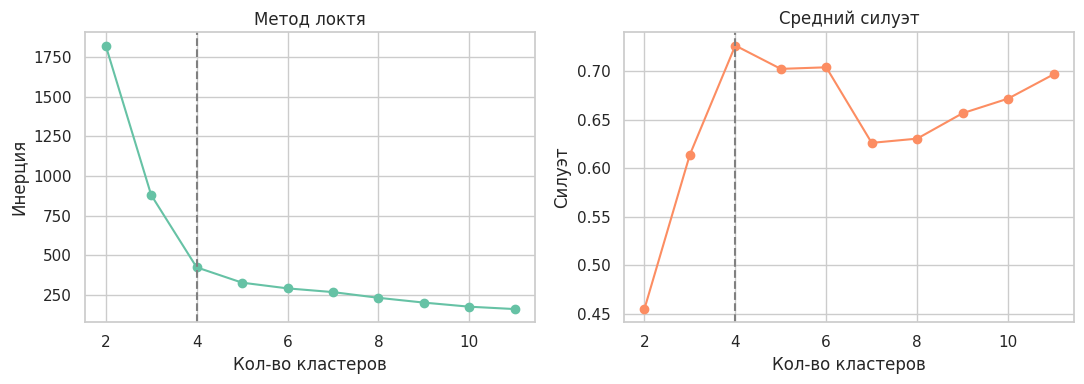

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scores.k, scores.inertia, "o-")
axes[0].set(title="Метод локтя", xlabel="Кол-во кластеров", ylabel="Инерция")

axes[1].plot(scores.k, scores.silhouette, "o-", color="C1")
axes[1].set(title="Средний силуэт", xlabel="Кол-во кластеров", ylabel="Силуэт")
for ax in axes:
    ax.axvline(4, ls="--", color="grey")
plt.tight_layout()
plt.show()

**Вывод:**   
Из графиков метода Локтя и метода Силуэта видно, что оптимальное число **кластеров = 4**, тк это точка перегиба в методе Локтя и максимальная точка в методе Силуэта.   
Это так же подтвержается анализом вопросов, где можно выделить 4 группы применения леденцов:
  * Для свежести дыхания;
  * Для концентрации;
  * Как сладкое;
  * Для ослабления симптомов болезни.  

### Кластеризация при k=4

In [ ]:
K = 4

km = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit(df)

Посмотрим как распределилось мнение респондентов по кластерам.

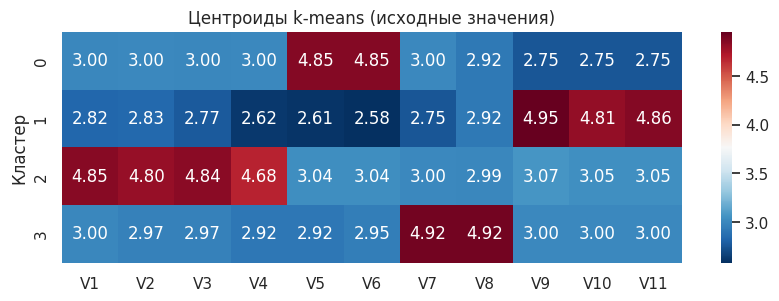

In [ ]:
centers = pd.DataFrame(km.cluster_centers_, columns=df.columns)
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(centers, annot=True, fmt=".2f", cmap="RdBu_r", ax=ax)
ax.set(title="Центроиды k-means (исходные значения)", ylabel="Кластер")
plt.show()

Присваиваем кластеру индекс для определения группы респондентов, как в иерархическом анализе, чтобы в дальнейшем их можно было сопоставить.

In [ ]:
# Словарь соотвествия индекса кластера с иерархическим анализом
mapping_dict = {}
for idx, row in pd.DataFrame(km.cluster_centers_, columns=df.columns).iterrows():
    if row[['V9', 'V10', 'V11']].mean() > 4:
        mapping_dict[idx] = 1  # Медицинские
    elif row[['V1', 'V2', 'V3', 'V4']].mean() > 4:
        mapping_dict[idx] = 2  # Освежающие
    elif row[['V7', 'V8']].mean() > 4:
        mapping_dict[idx] = 3  # Для концентрации
    elif row[['V5', 'V6']].mean() > 4:
        mapping_dict[idx] = 4  # Сладкоежки

df['cluster'] = pd.Series(km.labels_).map(mapping_dict)


Видно 4 группы:
  1) Медицинские: V9, V10, V11;
  2) Освежающие: V1, V2, V3, V4;
  3) Для концентрации: V7, V8;
  4) Сладкоежки: V5, V6.



In [ ]:
counts = df['cluster'].value_counts()
summary_table = pd.DataFrame([
    {"Номер кластера": 1, "Название": "Медицинские", "Количество наблюдений": counts.get(1, 0), "Какие вопросы относятся": "V9, V10, V11"},
    {"Номер кластера": 2, "Название": "Освежающие", "Количество наблюдений": counts.get(2, 0), "Какие вопросы относятся": "V1, V2, V3, V4"},
    {"Номер кластера": 3, "Название": "Для концентрации", "Количество наблюдений": counts.get(3, 0), "Какие вопросы относятся": "V7, V8"},
    {"Номер кластера": 4, "Название": "Сладкоежки", "Количество наблюдений": counts.get(4, 0), "Какие вопросы относятся": "V5, V6"}
])

summary_table.style.hide(axis='index', )

Номер кластера,Название,Количество наблюдений,Какие вопросы относятся
1,Медицинские,108,"V9, V10, V11"
2,Освежающие,110,"V1, V2, V3, V4"
3,Для концентрации,59,"V7, V8"
4,Сладкоежки,61,"V5, V6"


### График кластеризации

/tmp/ipykernel_6050/4103080966.py:43: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  circle = patches.Circle(


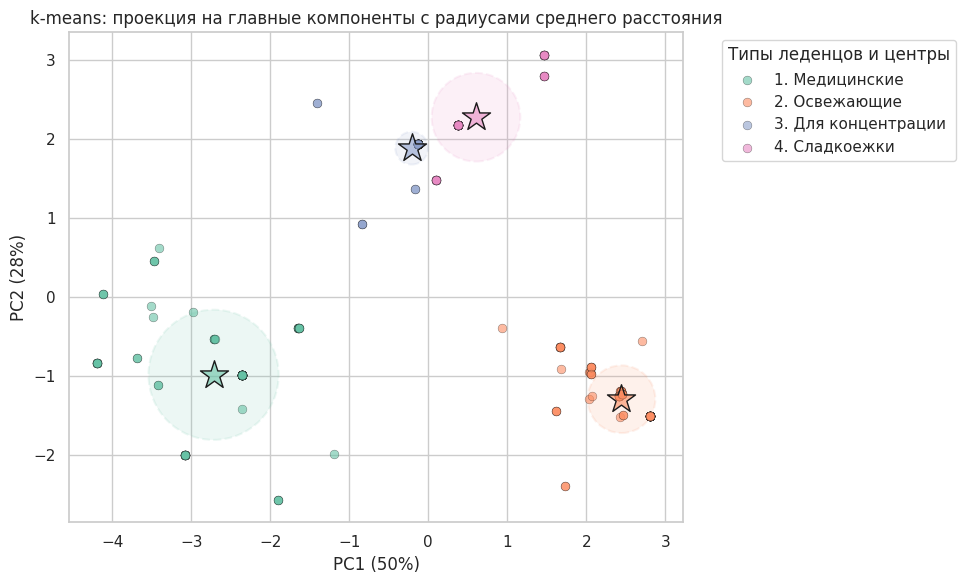

In [ ]:
cluster_names = {
    1: "1. Медицинские",
    2: "2. Освежающие",
    3: "3. Для концентрации",
    4: "4. Сладкоежки",
}

feature_cols = [c for c in df.columns if c != "cluster"]
X = df[feature_cols]

# Понижаем размерность и обучаем PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy_pca = pca.fit_transform(X)
labels_km = df["cluster"].values

fig, ax = plt.subplots(figsize=(11, 6))

# Рисуем точки, центроиды и радиусы среднего расстояния
for c in sorted(set(labels_km)):
    mask = labels_km == c
    name = cluster_names.get(c, f"Кластер {c}")
    ax.scatter(
        *xy_pca[mask].T,
        s=40,
        alpha=0.6,
        edgecolor="k",
        linewidth=0.3,
        label=name,
    )

    current_color = ax.collections[-1].get_facecolor()


    cluster_center = xy_pca[mask].mean(axis=0)
    distances = np.sqrt(np.sum((xy_pca[mask] - cluster_center) ** 2, axis=1))
    mean_distance = distances.mean()

    circle = patches.Circle(
        (cluster_center[0], cluster_center[1]),
        radius=mean_distance,
        color=current_color,
        alpha=0.12,
        linestyle="--",
        linewidth=1.5,
        edgecolor=current_color,
    )
    ax.add_patch(circle)

    ax.scatter(
        cluster_center[0],
        cluster_center[1],
        marker="*",
        s=450,
        c=current_color,
        edgecolor="k",
        linewidth=1,
    )

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title(
    "k-means: проекция на главные компоненты с радиусами среднего расстояния"
)
ax.legend(
    bbox_to_anchor=(1.05, 1), loc="upper left", title="Типы леденцов и центры"
)

ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()


## Устойчивость  
Ллойд сходится к локальному минимуму. Запустим k-means с 10 разными random_state при n_init=1 и n_init=10 и сравним каждое разбиение с нашим по скорректированному индексу Рэнда (ARI равен 1 при совпадении с точностью до перенумерации).

In [ ]:
for n_init in (1, 10):
    runs = [KMeans(n_clusters=K, n_init=n_init, random_state=seed).fit(X) for seed in range(20)]
    ari = np.array([adjusted_rand_score(labels_km, m.labels_) for m in runs])
    inertia = np.array([m.inertia_ for m in runs])
    print(f"n_init={n_init:>2}: то же разбиение в {np.mean(np.isclose(ari, 1)):.0%} запусков, "
          f"инерция {inertia.min():.2f}..{inertia.max():.2f}, ARI {ari.min():.2f}..{ari.max():.2f}")

n_init= 1: то же разбиение в 90% запусков, инерция 423.14..804.32, ARI 0.74..1.00
n_init=10: то же разбиение в 100% запусков, инерция 423.14..423.14, ARI 1.00..1.00


**Вывод:**   
Наше разбиение находится при первом старте в 90% случаях, значит n_init=10, здесь не так сильно нужен.

## Сравнение с методом Уорда

Используем `ARI` (Adjusted Rand Index - скорректированный индекс Рэнда).   
Он оценивает, насколько похожи два разных разбиения данных на кластеры.

In [ ]:
labels_ward = fcluster(linkage(X, "ward"), K, criterion="maxclust")

# Индекс сходства ARI
print("ARI(k-means, Ward) =", round(adjusted_rand_score(labels_km, labels_ward), 3))
display(pd.crosstab(pd.Series(labels_ward, name="Ward"), pd.Series(labels_km, name="k-means")))
moved = labels_ward != labels_km
df[moved].assign(Ward=labels_ward[moved], KMeans=labels_km[moved])


ARI(k-means, Ward) = 1.0


k-means,1,2,3,4
Ward,,,,
1,108,0,0,0
2,0,110,0,0
3,0,0,59,0
4,0,0,0,61


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,cluster,Ward,KMeans


**Вывод:**  
Метод Уорда совпал с методом k-means

## Выводы    
1. `Количество кластеров:` **4**, при `n_init`=**10**.    
2. Метод Уорда и k-means одинаково кластеризовали данные. Это означает, что выявленная структура кластеров является объективной.

3. Выделены следующие сегменты:   
  * `Медецинские`. 108 человек используют леденцы в медецинских целях, для ослабления симптомов болезни;
  * `Освежающие`. 110 человек используют леденцы для освежения дыхания.
  * `Для концентрации`. 59 человек используют леденцы для концентрации.
  * `Сладкоежки`. 61 человек используют леденцы как замену сладкого.

При производстве леденцов стоит обращать внимание на потребителей этих групп, особенно на группы `Медецинские` и `Освежающие`, тк большинство респондентов причисляют себя к этой группе.